In [2]:
#importing libraries used in EDA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#making a dataframe for delivery_data.csv
df=pd.read_csv('delivery_data.csv')
df_columns=df.columns
#printing Columns and number of column
print(df_columns,f'\nTotal Features:-\t{len(df_columns)}')

Index(['data', 'trip_creation_time', 'route_schedule_uuid', 'route_type',
       'trip_uuid', 'source_center', 'source_name', 'destination_center',
       'destination_name', 'od_start_time', 'od_end_time',
       'start_scan_to_end_scan', 'is_cutoff', 'cutoff_factor',
       'cutoff_timestamp', 'actual_distance_to_destination', 'actual_time',
       'osrm_time', 'osrm_distance', 'factor', 'segment_actual_time',
       'segment_osrm_time', 'segment_osrm_distance', 'segment_factor'],
      dtype='object') 
Total Features:-	24


In [3]:
#Getting top 2 rows to see how our data look like
df.head(2)

,data,trip_creation_time,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,od_start_time,...,cutoff_timestamp,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,factor,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor
0,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:27:55,10.435660,14.0,11.0,11.9653,1.272727,14.0,11.0,11.9653,1.272727
1,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:17:55,18.936842,24.0,20.0,21.7243,1.200000,10.0,9.0,9.7590,1.111111


In [4]:
#checking if Null values are present
df.isnull().sum()

data                                0
trip_creation_time                  0
route_schedule_uuid                 0
route_type                          0
trip_uuid                           0
source_center                       0
source_name                       293
destination_center                  0
destination_name                  261
od_start_time                       0
od_end_time                         0
start_scan_to_end_scan              0
is_cutoff                           0
cutoff_factor                       0
cutoff_timestamp                    0
actual_distance_to_destination      0
actual_time                         0
osrm_time                           0
osrm_distance                       0
factor                              0
segment_actual_time                 0
segment_osrm_time                   0
segment_osrm_distance               0
segment_factor                      0
dtype: int64

In [5]:
#printing the rows containing any nulls in any column
null_rows = df[df.isnull().any(axis=1)]
null_rows

,data,trip_creation_time,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,od_start_time,...,cutoff_timestamp,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,factor,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor
110,training,2018-09-25 08:53:04.377810,thanos::sroute:4460a38d-ab9b-484e-bd4e-f4201d0...,FTL,trip-153786558437756691,IND342601AAA,Piparcity_BsstdDPP_D (Rajasthan),IND342902A1B,NaN,2018-09-26 05:04:49.254901,...,2018-09-26 05:57:25,24.538214,58.0,33.0,30.8845,1.757576,58.0,33.0,30.8845,1.757576
111,training,2018-09-25 08:53:04.377810,thanos::sroute:4460a38d-ab9b-484e-bd4e-f4201d0...,FTL,trip-153786558437756691,IND342601AAA,Piparcity_BsstdDPP_D (Rajasthan),IND342902A1B,NaN,2018-09-26 05:04:49.254901,...,2018-09-26 05:04:49.254901,34.657709,110.0,43.0,41.5361,2.558140,52.0,10.0,10.6517,5.200000
112,training,2018-09-25 08:53:04.377810,thanos::sroute:4460a38d-ab9b-484e-bd4e-f4201d0...,FTL,trip-153786558437756691,IND342902A1B,NaN,IND302014AAA,Jaipur_Hub (Rajasthan),2018-09-26 06:58:08.054001,...,2018-09-26 14:09:19,22.783440,48.0,34.0,37.7749,1.411765,48.0,34.0,37.7749,1.411765
113,training,2018-09-25 08:53:04.377810,thanos::sroute:4460a38d-ab9b-484e-bd4e-f4201d0...,FTL,trip-153786558437756691,IND342902A1B,NaN,IND302014AAA,Jaipur_Hub (Rajasthan),2018-09-26 06:58:08.054001,...,2018-09-26 13:19:23,46.071250,98.0,41.0,56.3575,2.390244,49.0,33.0,34.1661,1.484848
114,training,2018-09-25 08:53:04.377810,thanos::sroute:4460a38d-ab9b-484e-bd4e-f4201d0...,FTL,trip-153786558437756691,IND342902A1B,NaN,IND302014AAA,Jaipur_Hub (Rajasthan),2018-09-26 06:58:08.054001,...,2018-09-26 12:49:33,67.714993,127.0,58.0,80.4811,2.189655,29.0,17.0,24.1236,1.705882
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144484,test,2018-10-03 09:06:06.690094,thanos::sroute:cbef3b6a-79ea-4d5e-a215-b558a70...,FTL,trip-153855756668984584,IND282002AAD,NaN,IND474003AAA,Gwalior_HrihrNgr_I (Madhya Pradesh),2018-10-03 17:34:21.835475,...,2018-10-03 20:54:08,45.134384,62.0,45.0,47.7734,1.377778,34.0,23.0,23.6601,1.478261
144485,test,2018-10-03 09:06:06.690094,thanos::sroute:cbef3b6a-79ea-4d5e-a215-b558a70...,FTL,trip-153855756668984584,IND282002AAD,NaN,IND474003AAA,Gwalior_HrihrNgr_I (Madhya Pradesh),2018-10-03 17:34:21.835475,...,2018-10-03 20:30:09,66.542266,86.0,71.0,71.9549,1.211268,23.0,25.0,24.1815,0.920000
144486,test,2018-10-03 09:06:06.690094,thanos::sroute:cbef3b6a-79ea-4d5e-a215-b558a70...,FTL,trip-153855756668984584,IND282002AAD,NaN,IND474003AAA,Gwalior_HrihrNgr_I (Madhya Pradesh),2018-10-03 17:34:21.835475,...,2018-10-03 20:00:08,88.143957,116.0,114.0,112.6943,1.017544,30.0,43.0,40.7394,0.697674
144487,test,2018-10-03 09:06:06.690094,thanos::sroute:cbef3b6a-79ea-4d5e-a215-b558a70...,FTL,trip-153855756668984584,IND282002AAD,NaN,IND474003AAA,Gwalior_HrihrNgr_I (Madhya Pradesh),2018-10-03 17:34:21.835475,...,2018-10-03 19:02:11,111.084417,173.0,123.0,134.1940,1.406504,57.0,45.0,46.9217,1.266667


In [6]:
#we replace if our any row contain string type of null to actual NaN type in 
string_nulls = ['nan','NaN','Null','UNKNOWN','unknown','']
df['source_name'] = df['source_name'].replace(string_nulls,np.nan)
df['source_name'] = df['destination_name'].replace(string_nulls,np.nan)

In [7]:
#building our source lookup dictionary.
source_lookup = df.dropna(subset=['source_name']).set_index('source_center')['source_name'].to_dict()
source_lookup

{'IND388121AAA': 'Khambhat_MotvdDPP_D (Gujarat)',
 'IND388620AAB': 'Anand_Vaghasi_IP (Gujarat)',
 'IND421302AAG': 'Pune_Tathawde_H (Maharashtra)',
 'IND400011AAA': 'Mumbai_Chndivli_PC (Maharashtra)',
 'IND562132AAA': 'Bengaluru_Peenya_L (Karnataka)',
 'IND560099AAB': 'Bengaluru_KGAirprt_HB (Karnataka)',
 'IND141003AAB': 'Jagraon_DC (Punjab)',
 'IND142026AAA': 'Raikot_DC (Punjab)',
 'IND141109AAA': 'Ludhiana_MilrGanj_HB (Punjab)',
 'IND362001AAA': 'Junagadh_keshod_DC (Gujarat)',
 'IND362265AAA': 'Kodinar_NCplxDPP_D (Gujarat)',
 'IND362720AAA': 'Una_Mamlatdr_DC (Gujarat)',
 'IND362560AAA': 'Talala_SsnRdDPP_D (Gujarat)',
 'IND362150AAA': 'Junagadh_DPC (Gujarat)',
 'IND131028AAB': 'Gurgaon_Bilaspur_HB (Haryana)',
 'IND247667AAB': 'Haridwar (Uttarakhand)',
 'IND249407AAA': 'Kotdwara_Nzbadrd_D (Uttarakhand)',
 'IND600056AAB': 'Chennai_Hub (Tamil Nadu)',
 'IND000000ACA': 'Chandigarh_Mehmdpur_H (Punjab)',
 'IND144001AAB': 'Amritsar_DPC (Punjab)',
 'IND122004AAA': 'Gurgaon_Bilaspur_HB (Haryana)

In [8]:
#building our destination lookup dictionary.
dest_lookup = df.dropna(subset=['destination_name']).set_index('destination_center')['destination_name'].to_dict()

In [9]:
#applying lookup and filling our source and destination name with source_center Id and destination center id
df['source_name'] = df['source_name'].fillna(df['source_center'].map(source_lookup))
df['destination_name'] = df['destination_name'].fillna(df['destination_center'].map(source_lookup))

In [10]:
#still many contain such destination which have no name
df.isnull().sum()

data                               0
trip_creation_time                 0
route_schedule_uuid                0
route_type                         0
trip_uuid                          0
source_center                      0
source_name                       13
destination_center                 0
destination_name                  21
od_start_time                      0
od_end_time                        0
start_scan_to_end_scan             0
is_cutoff                          0
cutoff_factor                      0
cutoff_timestamp                   0
actual_distance_to_destination     0
actual_time                        0
osrm_time                          0
osrm_distance                      0
factor                             0
segment_actual_time                0
segment_osrm_time                  0
segment_osrm_distance              0
segment_factor                     0
dtype: int64

In [11]:
#we fill this with their Ids using lambdas
df['source_name'] = df['source_name'].fillna(df['source_center'].apply(lambda x:f'hub{x}'))
df['destination_name'] = df['destination_name'].fillna(df['destination_center'].apply(lambda x:f'hub{x}'))

In [12]:
df.isnull().sum()

data                              0
trip_creation_time                0
route_schedule_uuid               0
route_type                        0
trip_uuid                         0
source_center                     0
source_name                       0
destination_center                0
destination_name                  0
od_start_time                     0
od_end_time                       0
start_scan_to_end_scan            0
is_cutoff                         0
cutoff_factor                     0
cutoff_timestamp                  0
actual_distance_to_destination    0
actual_time                       0
osrm_time                         0
osrm_distance                     0
factor                            0
segment_actual_time               0
segment_osrm_time                 0
segment_osrm_distance             0
segment_factor                    0
dtype: int64

In [13]:
#printing total number of source and destination hub using unique then applying set on them
source_hub = set(df['source_center'].unique())
dest_hub = set(df['destination_center'].unique())
nodes = source_hub | dest_hub
print(f'Total Rows:-\t\t{df.shape[0]}\nTotal Unique Trips:\t{len(df['trip_uuid'].unique())}\nTotal Edges\corridors:-\t{len(df['route_schedule_uuid'].unique())}\nTotal Source Hub:-\t{len(source_hub)}\nTotal Destination hub:-\t{len(dest_hub)}\nTotal Nodes:-\t\t{len(nodes)}')

Total Rows:-		144867
Total Unique Trips:	14817
Total Edges\corridors:-	1504
Total Source Hub:-	1508
Total Destination hub:-	1481
Total Nodes:-		1657


<>:4: SyntaxWarning: invalid escape sequence '\c'
<>:4: SyntaxWarning: invalid escape sequence '\c'
C:\Users\NISHANT SHARMA\AppData\Local\Temp\ipykernel_25484\3733651478.py:4: SyntaxWarning: invalid escape sequence '\c'
  print(f'Total Rows:-\t\t{df.shape[0]}\nTotal Unique Trips:\t{len(df['trip_uuid'].unique())}\nTotal Edges\corridors:-\t{len(df['route_schedule_uuid'].unique())}\nTotal Source Hub:-\t{len(source_hub)}\nTotal Destination hub:-\t{len(dest_hub)}\nTotal Nodes:-\t\t{len(nodes)}')


In [21]:
#printing kurtosis to know if our data is skewed or has heavy tails
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        print('='*10,col,"="*10)
        print('Skewness',df[col].skew())
        print('Kurtosis',df[col].kurtosis())

========== start_scan_to_end_scan ==========
Skewness 1.1106238814035019
Kurtosis -0.051148843443664216
========== is_cutoff ==========
Skewness -1.663320384910676
Kurtosis 0.7666452867947449
========== cutoff_factor ==========
Skewness 1.9920944107955658
Kurtosis 3.4011598743045357
========== actual_distance_to_destination ==========
Skewness 1.9911048254267962
Kurtosis 3.3976608966664865
========== actual_time ==========
Skewness 2.068065018967708
Kurtosis 3.962915001128731
========== osrm_time ==========
Skewness 2.045165965158788
Kurtosis 3.7557950772662934
========== osrm_distance ==========
Skewness 2.0482359055866546
Kurtosis 3.7344482401882586
========== factor ==========
Skewness 17.49081086215272
Kurtosis 491.1776405236298
========== segment_actual_time ==========
Skewness 16.827413001372527
Kurtosis 494.4963982693179
========== segment_osrm_time ==========
Skewness 19.639634311596556
Kurtosis 1444.5612433727829
========== segment_osrm_distance ==========
Skewness 26.58536297

In [22]:
#describing our target column
df['segment_osrm_time'].describe()

count    144867.000000
mean         18.507548
std          14.775960
min           0.000000
25%          11.000000
50%          17.000000
75%          22.000000
max        1611.000000
Name: segment_osrm_time, dtype: float64

In [23]:
type(df['segment_osrm_time'])

pandas.core.series.Series

In [24]:
'''getting the columns which has
heavy outliers and highly skewed'''
heavy_outliers = ['segment_factor','segment_osrm_distance','segment_osrm_time','segment_actual_time','factor']
highly_skewed = ['segment_factor','segment_osrm_distance','segment_osrm_time','segment_actual_time','factor']

C:\Users\NISHANT SHARMA\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\NISHANT SHARMA\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


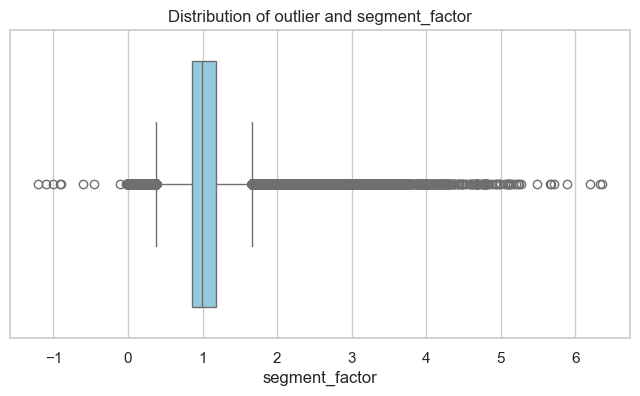

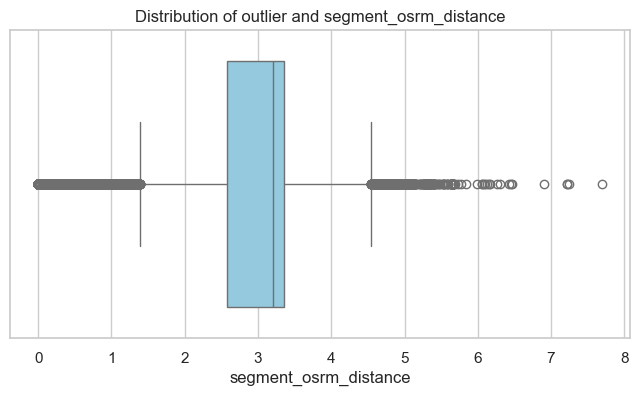

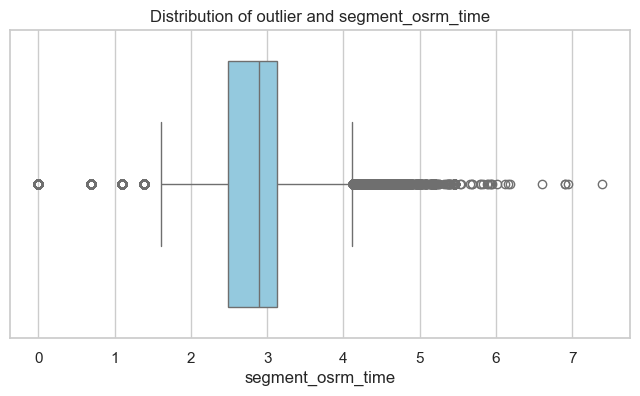

C:\Users\NISHANT SHARMA\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\NISHANT SHARMA\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


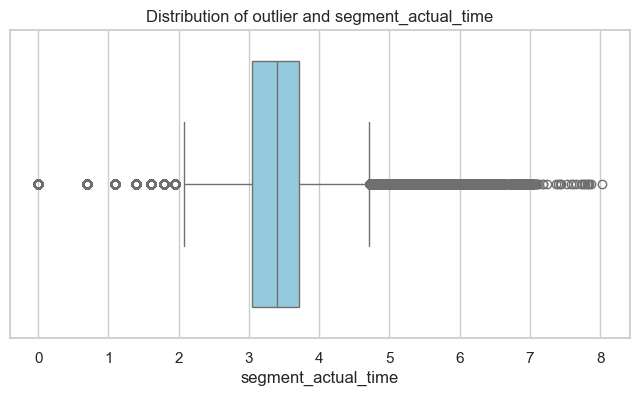

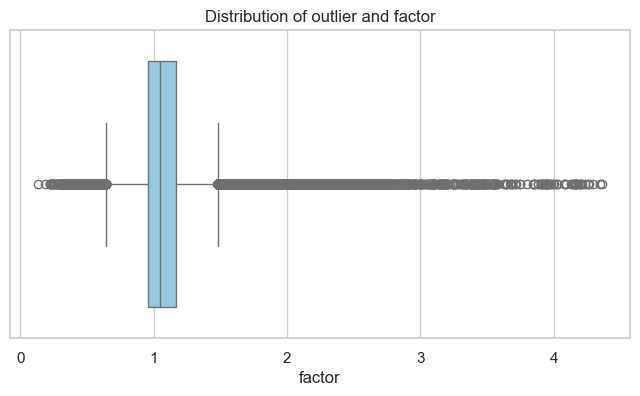

In [25]:
'''getting the boxplot
    for our heavy outliers table'''
for i in heavy_outliers:
    sns.set_theme(style='whitegrid')
    plt.figure(figsize=(8,4))
    sns.boxplot(x=np.log1p(df[i]),color='skyblue')
    plt.title(f'Distribution of outlier and {i}')
    plt.xlabel(f'{i}')
    plt.show()

In [26]:
'''printinh the number of 
    outliers in our heavy outliers columns'''
for i in heavy_outliers:
    count = 0
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = df[i].quantile(0.75)-df[i].quantile(0.25)
    lb = Q1-1.5*IQR
    ub = Q3+1.5*IQR
    outlier_mask = (df[i]<lb) | (df[i]>ub)
    count = outlier_mask.sum()
    print(f'Total outliers in {i} are:-\t{count}')

Total outliers in segment_factor are:-	13976
Total outliers in segment_osrm_distance are:-	4315
Total outliers in segment_osrm_time are:-	6378
Total outliers in segment_actual_time are:-	9298
Total outliers in factor are:-	11429


In [27]:
''' printing how much
    deliveries has FTL and Carting'''
df['route_type'].value_counts()

route_type
FTL        99660
Carting    45207
Name: count, dtype: int64

In [28]:
'''adding a column of segment wise 
    ratio of segment_actual_time/segment osrm time'''
df['segment_ratio'] = df['segment_actual_time']/df['segment_osrm_time']

In [29]:
'''since our data is has 
   heavy outliers we convert 
   them into log transform to apply linear
   Regression and other baseline models'''
for col in heavy_outliers:
    df[f'log_{col}'] = np.log1p(df[col])

C:\Users\NISHANT SHARMA\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\NISHANT SHARMA\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\NISHANT SHARMA\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\NISHANT SHARMA\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [30]:
#printing our data again to look how our data look after log transform
df.head()

,data,trip_creation_time,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,od_start_time,...,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor,segment_ratio,log_segment_factor,log_segment_osrm_distance,log_segment_osrm_time,log_segment_actual_time,log_factor
0,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Khambhat_MotvdDPP_D (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,14.0,11.0,11.9653,1.272727,1.272727,0.820981,2.562277,2.484907,2.708050,0.820981
1,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Khambhat_MotvdDPP_D (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,10.0,9.0,9.7590,1.111111,1.111111,0.747214,2.375743,2.302585,2.397895,0.788457
2,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Khambhat_MotvdDPP_D (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,16.0,7.0,10.8152,2.285714,2.285714,1.189584,2.469387,2.079442,2.833213,0.887303
3,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Khambhat_MotvdDPP_D (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,21.0,12.0,13.0224,1.750000,1.750000,1.011601,2.640656,2.564949,3.091042,0.936093
4,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Khambhat_MotvdDPP_D (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,6.0,5.0,3.9153,1.200000,1.200000,0.788457,1.592353,1.791759,1.945910,0.934309


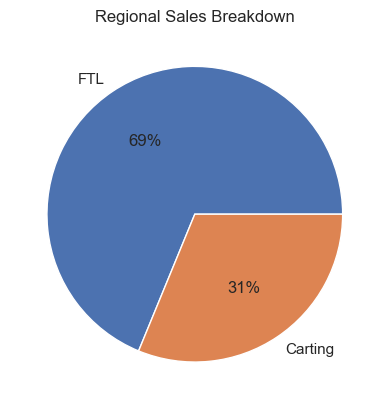

In [31]:
'''printing the pie chart to
    demonstrate how much is FTL 
    and how much is Carting'''

data = [99660,45207]
labels = ['FTL','Carting']

plt.pie(data, labels=labels,autopct='%1.0f%%')
plt.title('Regional Sales Breakdown')
plt.show()

In [33]:
'''saving our semi-cleaned data file 
    as delihvery_cleaned.csv saving as index=False
    so that no new column is added with index 0,1,2...'''
df.to_csv('delihvery_cleaned.csv',index=False)

In [5]:
df['log_actual_time'] = df['actual_time']